In [ ]:

import sys

print("Python version:", sys.version)
print("Our project is ready!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Our project is ready!


In [ ]:

import pandas as pd

data = {
    "Date": [
        "2026-01-01", "2026-01-02", "2026-01-03",
        "2026-01-04", "2026-01-05", "2026-01-06",
        "2026-01-07", "2026-01-08", "2026-01-09",
        "2026-01-10"
    ],
    "Product": [
        "Laptop", "Mouse", "Laptop", "Keyboard", "Mouse",
        "Laptop", "Keyboard", "Mouse", "Laptop", "Keyboard"
    ],
    "Quantity": [2, 10, 3, 5, 8, 4, 6, 12, 3, 7],
    "Unit_Price": [
        80000, 1500, 80000, 3000, 1500,
        80000, 3000, 1500, 80000, 3000
    ]
}

df = pd.DataFrame(data)

print("Sales Dataset Created Successfully!")
print(df)

df["Revenue"] = df["Quantity"] * df["Unit_Price"]

print(df)


Sales Dataset Created Successfully!
         Date   Product  Quantity  Unit_Price
0  2026-01-01    Laptop         2       80000
1  2026-01-02     Mouse        10        1500
2  2026-01-03    Laptop         3       80000
3  2026-01-04  Keyboard         5        3000
4  2026-01-05     Mouse         8        1500
5  2026-01-06    Laptop         4       80000
6  2026-01-07  Keyboard         6        3000
7  2026-01-08     Mouse        12        1500
8  2026-01-09    Laptop         3       80000
9  2026-01-10  Keyboard         7        3000
         Date   Product  Quantity  Unit_Price  Revenue
0  2026-01-01    Laptop         2       80000   160000
1  2026-01-02     Mouse        10        1500    15000
2  2026-01-03    Laptop         3       80000   240000
3  2026-01-04  Keyboard         5        3000    15000
4  2026-01-05     Mouse         8        1500    12000
5  2026-01-06    Laptop         4       80000   320000
6  2026-01-07  Keyboard         6        3000    18000
7  2026-01-08     

In [ ]:

total_revenue = df["Revenue"].sum()

print("Total Revenue: Rs.", total_revenue)

product_sales = df.groupby("Product")["Revenue"].sum()

print("Product-wise Revenue:")
print(product_sales)


Total Revenue: Rs. 1059000
Product-wise Revenue:
Product
Keyboard     54000
Laptop      960000
Mouse        45000
Name: Revenue, dtype: int64


In [ ]:

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Calculate total revenue for each day
daily_sales = df.groupby("Date")["Revenue"].sum()

print("Daily Sales Revenue:")
print(daily_sales)


Daily Sales Revenue:
Date
2026-01-01    160000
2026-01-02     15000
2026-01-03    240000
2026-01-04     15000
2026-01-05     12000
2026-01-06    320000
2026-01-07     18000
2026-01-08     18000
2026-01-09    240000
2026-01-10     21000
Name: Revenue, dtype: int64


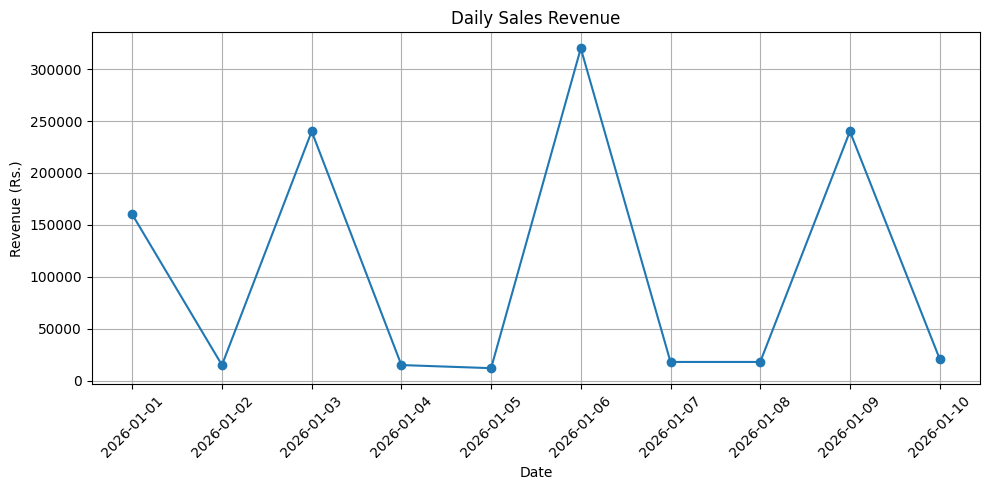

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    marker="o"
)

plt.title("Daily Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()


In [ ]:

sales_df = daily_sales.reset_index()

sales_df.columns = ["Date", "Revenue"]

print(sales_df)


        Date  Revenue
0 2026-01-01   160000
1 2026-01-02    15000
2 2026-01-03   240000
3 2026-01-04    15000
4 2026-01-05    12000
5 2026-01-06   320000
6 2026-01-07    18000
7 2026-01-08    18000
8 2026-01-09   240000
9 2026-01-10    21000


In [ ]:

sales_df["Day_Number"] = range(1, len(sales_df) + 1)

print(sales_df)


        Date  Revenue  Day_Number
0 2026-01-01   160000           1
1 2026-01-02    15000           2
2 2026-01-03   240000           3
3 2026-01-04    15000           4
4 2026-01-05    12000           5
5 2026-01-06   320000           6
6 2026-01-07    18000           7
7 2026-01-08    18000           8
8 2026-01-09   240000           9
9 2026-01-10    21000          10


In [ ]:

from sklearn.linear_model import LinearRegression

# Input feature
X = sales_df[["Day_Number"]]

# Target
y = sales_df["Revenue"]

# Create the model
model = LinearRegression()

# Train the model
model.fit(X, y)

print("Model trained successfully!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

# Predict sales for the next 5 days
future_days = pd.DataFrame({
    "Day_Number": [11, 12, 13, 14, 15]
})

future_days["Predicted_Revenue"] = model.predict(
    future_days[["Day_Number"]]
)

print(future_days.round(2))


Model trained successfully!
Slope: -2842.424242424243
Intercept: 121533.33333333334
   Day_Number  Predicted_Revenue
0          11           90266.67
1          12           87424.24
2          13           84581.82
3          14           81739.39
4          15           78896.97


In [ ]:

# Predict sales for the days we already have
sales_df["Predicted_Revenue"] = model.predict(
    sales_df[["Day_Number"]]
)

# Compare actual and predicted revenue
print(
    sales_df[
        ["Date", "Revenue", "Predicted_Revenue"]
    ].round(2)
)


        Date  Revenue  Predicted_Revenue
0 2026-01-01   160000          118690.91
1 2026-01-02    15000          115848.48
2 2026-01-03   240000          113006.06
3 2026-01-04    15000          110163.64
4 2026-01-05    12000          107321.21
5 2026-01-06   320000          104478.79
6 2026-01-07    18000          101636.36
7 2026-01-08    18000           98793.94
8 2026-01-09   240000           95951.52
9 2026-01-10    21000           93109.09


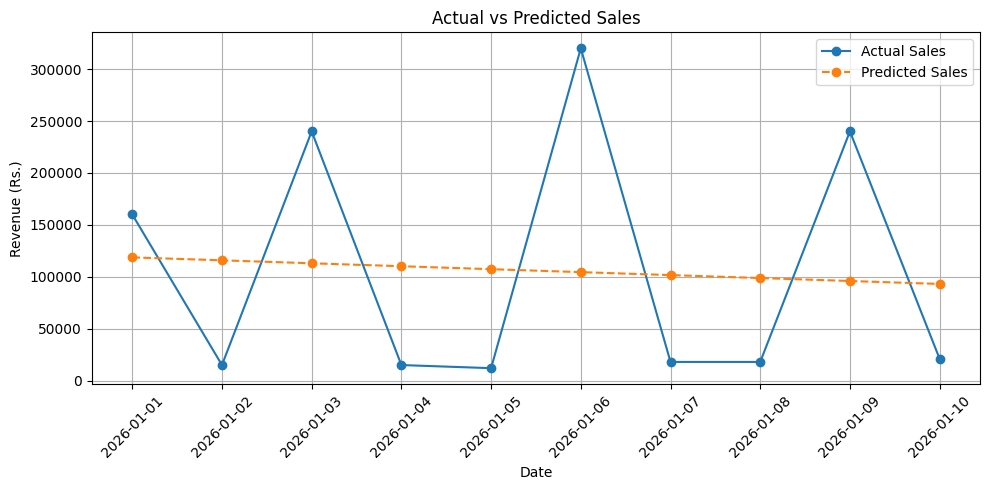

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    sales_df["Date"],
    sales_df["Revenue"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    sales_df["Date"],
    sales_df["Predicted_Revenue"],
    marker="o",
    linestyle="--",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


In [ ]:

from sklearn.metrics import mean_absolute_error

actual = sales_df["Revenue"]
predicted = sales_df["Predicted_Revenue"]

mae = mean_absolute_error(actual, predicted)

print("Mean Absolute Error (MAE): Rs.", round(mae, 2))


Mean Absolute Error (MAE): Rs. 105574.55


In [ ]:

# Keep the data in chronological order
sales_df = sales_df.sort_values("Date").reset_index(drop=True)

# First 8 days: training data
train = sales_df.iloc[:8].copy()

# Last 2 days: testing data
test = sales_df.iloc[8:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTest dates:")
print(test[["Date", "Revenue"]])


Training rows: 8
Testing rows: 2

Test dates:
        Date  Revenue
8 2026-01-09   240000
9 2026-01-10    21000


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Select training features and target
X_train = train[["Day_Number"]]
y_train = train["Revenue"]

# Select test features and actual target
X_test = test[["Day_Number"]]
y_test = test["Revenue"]

# Create and train a fresh model
test_model = LinearRegression()
test_model.fit(X_train, y_train)

# Predict unseen test data
test_predictions = test_model.predict(X_test)

# Evaluate predictions
mae = mean_absolute_error(y_test, test_predictions)

print("Actual Revenue:", y_test.tolist())
print("Predicted Revenue:", test_predictions.round(2).tolist())
print("Test MAE: Rs.", round(mae, 2))


Actual Revenue: [240000, 21000]
Predicted Revenue: [60000.0, 51166.67]
Test MAE: Rs. 105083.33


In [ ]:

# Create a clean test results table
results_df = test[["Date", "Revenue"]].copy()

results_df["Predicted_Revenue"] = test_predictions.round(2)

results_df["Absolute_Error"] = (
    results_df["Revenue"] - results_df["Predicted_Revenue"]
).abs().round(2)

print(results_df)

# Export test results to a CSV file
results_df.to_csv(
    "sales_forecast_results.csv",
    index=False
)

print("CSV file created successfully!")


        Date  Revenue  Predicted_Revenue  Absolute_Error
8 2026-01-09   240000           60000.00       180000.00
9 2026-01-10    21000           51166.67        30166.67
CSV file created successfully!


In [ ]:

from google.colab import files

files.download("sales_forecast_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Create the next 5 future days
future_days = pd.DataFrame({
    "Day_Number": [11, 12, 13, 14, 15]
})

# Generate predictions using the model trained on training data
future_days["Predicted_Revenue"] = test_model.predict(
    future_days[["Day_Number"]]
)

# Assign future dates
future_days["Date"] = pd.date_range(
    start=sales_df["Date"].max() + pd.Timedelta(days=1),
    periods=5,
    freq="D"
)

# Arrange columns for Power BI
future_forecast = future_days[
    ["Date", "Day_Number", "Predicted_Revenue"]
]

print(future_forecast.round(2))

# Save future predictions as a CSV file
future_forecast.to_csv(
    "future_sales_forecast.csv",
    index=False
)

print("Future forecast CSV created successfully!")

from google.colab import files

files.download("future_sales_forecast.csv")


        Date  Day_Number  Predicted_Revenue
0 2026-01-11          11           42333.33
1 2026-01-12          12           33500.00
2 2026-01-13          13           24666.67
3 2026-01-14          14           15833.33
4 2026-01-15          15            7000.00
Future forecast CSV created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Compare actual vs predicted sales on test data
evaluation = results_df[["Revenue", "Predicted_Revenue"]].copy()

mae = mean_absolute_error(
    evaluation["Revenue"],
    evaluation["Predicted_Revenue"]
)

rmse = np.sqrt(mean_squared_error(
    evaluation["Revenue"],
    evaluation["Predicted_Revenue"]
))

print("Model Evaluation")
print("----------------")
print(f"MAE:  Rs. {mae:,.2f}")
print(f"RMSE: Rs. {rmse:,.2f}")


NameError: name 'results_df' is not defined

In [ ]:

print("sales_df exists:", "sales_df" in globals())
print("test exists:", "test" in globals())
print("test_predictions exists:", "test_predictions" in globals())
print("results_df exists:", "results_df" in globals())


sales_df exists: False
test exists: False
test_predictions exists: False
results_df exists: False
